# Final objects check

Cagri's annotated objects (whole tissue and fibroblast/decidual, mouse and human) against the QC'd objects they were
built from (the objects sent on Nov 6, `SENT`). For each species:

1. nuclei: fib/dec object ⊂ whole-tissue object ⊂ SENT, by nucleus ID
2. genes: the same genes as SENT, or a subset of them
3. counts: `layers['raw_counts']` identical to SENT `layers['counts']` for every shared nucleus
4. labels: `cell_type` agrees between the fib/dec and whole-tissue objects (the disagreements are listed)
5. positions: the fib/dec object's `_nick` and `_andy` columns equal SENT's; which set the whole-tissue
   `x_um_dbscan`/`y_um_dbscan` columns are
6. subtype counts, and a UMAP of the fib/dec object colored by subtype

Writes `checks/final_objects_check_<date>.tsv` and `checks/<species>_fibdec_umap.png` next to the objects.
Run in the `rsc_uv` kernel on a compute node with about 96 GB (one species' three objects are in memory at once).

In [1]:
import os
os.environ["HDF5_USE_FILE_LOCKING"] = "FALSE"

from datetime import date
from pathlib import Path

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Cagri's objects, copied into xmens_scripts (data/final_objects/2026_11_07); the originals are in
# /n/lab_storage/eddy_lab/Lab/mckinley/data. SENT = the QC'd objects with both position sets, sent Nov 6.
FINAL = Path("/n/lab_storage/eddy_lab/users/nhilgert/xmens_scripts/data/final_objects/2026_11_07")
SENT = Path("/n/netscratch/eddy_lab/Everyone/nhilgert/2026_11_06_qc_regen_nick_andy_coords")
OBJECTS = {
    "mouse": {"all": FINAL / "20261106_mouse_allcells_final.h5ad",
              "fibdec": FINAL / "20261106_mouse_OnlyFib_annotated_Final.h5ad",
              "sent": SENT / "qc_passed_mouse.h5ad"},
    "human": {"all": FINAL / "20261107_Human_allcells_final.h5ad",
              "fibdec": FINAL / "20261107_Human_OnlyFib_Annotated_Final.h5ad",
              "sent": SENT / "qc_passed_human.h5ad"},
}
OUT_DIR = FINAL / "checks"
OUT_DIR.mkdir(exist_ok=True)
for species, paths in OBJECTS.items():
    for role, path in paths.items():
        print(f"{species} {role}: {'found' if path.exists() else 'MISSING'}  {path}")

mouse all: found  /n/lab_storage/eddy_lab/users/nhilgert/xmens_scripts/data/final_objects/2026_11_07/20261106_mouse_allcells_final.h5ad
mouse fibdec: found  /n/lab_storage/eddy_lab/users/nhilgert/xmens_scripts/data/final_objects/2026_11_07/20261106_mouse_OnlyFib_annotated_Final.h5ad
mouse sent: found  /n/netscratch/eddy_lab/Everyone/nhilgert/2026_11_06_qc_regen_nick_andy_coords/qc_passed_mouse.h5ad
human all: found  /n/lab_storage/eddy_lab/users/nhilgert/xmens_scripts/data/final_objects/2026_11_07/20261107_Human_allcells_final.h5ad
human fibdec: found  /n/lab_storage/eddy_lab/users/nhilgert/xmens_scripts/data/final_objects/2026_11_07/20261107_Human_OnlyFib_Annotated_Final.h5ad
human sent: found  /n/netscratch/eddy_lab/Everyone/nhilgert/2026_11_06_qc_regen_nick_andy_coords/qc_passed_human.h5ad


## Helpers

In [2]:
def same_sparse(a, b):
    """True when two sparse matrices have identical values at identical positions."""
    return a.shape == b.shape and (a != b).nnz == 0


def same_floats(a, b):
    """Elementwise equality of two float arrays, NaN counting as equal to NaN."""
    return np.array_equal(np.asarray(a, float), np.asarray(b, float), equal_nan=True)


def positions(obs, suffix=""):
    """The columns x_um_dbscan<suffix>, y_um_dbscan<suffix> ('' , '_nick' or '_andy') as an (n, 2) float array."""
    return obs[[f"x_um_dbscan{suffix}", f"y_um_dbscan{suffix}"]].to_numpy(float)


def which_position_set(obs, sent_obs):
    """Name the SENT position set that an object's plain x_um_dbscan/y_um_dbscan columns equal, or 'neither'."""
    here = positions(obs)
    for name in ("nick", "andy"):
        if same_floats(here, positions(sent_obs.loc[obs.index], f"_{name}")):
            return name
    return "neither"


def counts_identical(obj, layer, sent):
    """Compare obj.layers[layer] with SENT counts on the shared nuclei; genes aligned to obj's var_names."""
    shared = obj.obs_names.intersection(sent.obs_names)
    if not set(obj.var_names) <= set(sent.var_names):
        return False, f"{len(set(obj.var_names) - set(sent.var_names))} genes not in SENT"
    reference = sent[shared, obj.var_names].layers["counts"]
    return same_sparse(obj[shared].layers[layer], reference), f"{len(shared):,} shared nuclei"


results = []   # one row per check: species, check, result, detail


def record(species, check, ok, detail=""):
    results.append({"species": species, "check": check, "ok": bool(ok), "detail": detail})
    print(f"  {'OK  ' if ok else 'FAIL'} {check}" + (f"  ({detail})" if detail else ""))

## Checks, one species at a time

=== mouse: whole tissue (57243, 32287), fib/dec (42966, 32287), SENT (69307, 32287)
  OK   fib/dec nuclei are a subset of the whole-tissue object  (42,966 of 57,243)
  OK   whole-tissue nuclei are a subset of SENT  (57,243 of 69,307; 12,064 removed in annotation)
  OK   whole-tissue genes identical to SENT  (32,287 genes)
  OK   fib/dec genes identical to SENT  (32,287 genes)
  OK   whole-tissue raw_counts identical to SENT counts  (57,243 shared nuclei)
  OK   fib/dec raw_counts identical to SENT counts  (42,966 shared nuclei)
  OK   cell_type agrees between fib/dec and whole-tissue objects  (0 nuclei differ)
  OK   every whole-tissue dec/eFib nucleus is in the fib/dec object  (42,966 dec/eFib in whole-tissue vs 42,966 in fib/dec)
  OK   fib/dec x/y_um_dbscan_nick equal SENT
  OK   fib/dec x/y_um_dbscan_andy equal SENT
  OK   fib/dec obsm['spatial_andy'] equals its _andy columns
  OK   whole-tissue x/y_um_dbscan are SENT's andy positions
  OK   fib/dec x/y_um_dbscan are SENT's nick po

nuclei
cell_type cell_subtype        
dec       dec1           10400
          dec2            6331
          dec3            4717
          decAp           1155
eFib      eFib1           1985
          eFib2           5734
          eFib2i          8025
          eFib3           3890
          eFibP            729

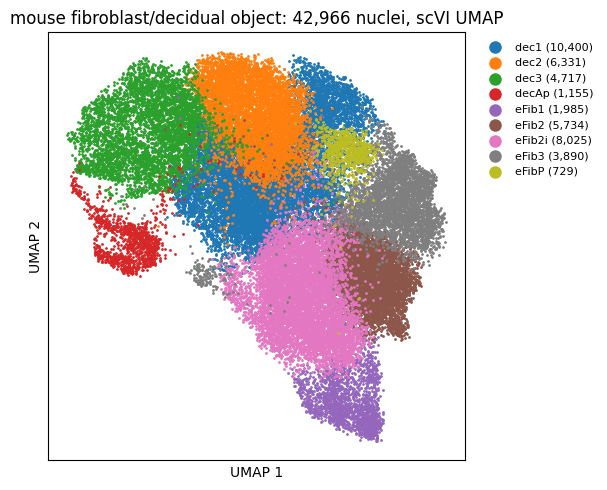

In [3]:
def check_species(species):
    paths = OBJECTS[species]
    whole = ad.read_h5ad(paths["all"])
    fibdec = ad.read_h5ad(paths["fibdec"])
    sent = ad.read_h5ad(paths["sent"])
    print(f"=== {species}: whole tissue {whole.shape}, fib/dec {fibdec.shape}, SENT {sent.shape}")

    # 1. nuclei
    record(species, "fib/dec nuclei are a subset of the whole-tissue object",
           fibdec.obs_names.isin(whole.obs_names).all(), f"{fibdec.n_obs:,} of {whole.n_obs:,}")
    record(species, "whole-tissue nuclei are a subset of SENT", whole.obs_names.isin(sent.obs_names).all(),
           f"{whole.n_obs:,} of {sent.n_obs:,}; {sent.n_obs - whole.n_obs:,} removed in annotation")

    # 2. genes
    for name, obj in (("whole-tissue", whole), ("fib/dec", fibdec)):
        if obj.var_names.equals(sent.var_names):
            record(species, f"{name} genes identical to SENT", True, f"{obj.n_vars:,} genes")
        else:
            record(species, f"{name} genes are a subset of SENT", set(obj.var_names) <= set(sent.var_names),
                   f"{obj.n_vars:,} of {sent.n_vars:,}")

    # 3. counts
    for name, obj in (("whole-tissue", whole), ("fib/dec", fibdec)):
        ok, detail = counts_identical(obj, "raw_counts", sent)
        record(species, f"{name} raw_counts identical to SENT counts", ok, detail)

    # 4. labels
    shared = fibdec.obs_names
    whole_labels = whole.obs.loc[shared, "cell_type"].astype(str).to_numpy()
    fibdec_labels = fibdec.obs["cell_type"].astype(str).to_numpy()
    n_differ = int((whole_labels != fibdec_labels).sum())
    record(species, "cell_type agrees between fib/dec and whole-tissue objects", n_differ == 0,
           f"{n_differ} nuclei differ")
    if n_differ:
        differ = whole_labels != fibdec_labels
        display(pd.crosstab(pd.Series(whole_labels[differ], name="whole-tissue cell_type"),
                            pd.Series(fibdec_labels[differ], name="fib/dec cell_type")))
    fib_only = set(fibdec.obs["cell_type"].astype(str))
    in_whole = whole.obs["cell_type"].astype(str).isin(fib_only)
    record(species, "every whole-tissue dec/eFib nucleus is in the fib/dec object",
           whole.obs_names[in_whole].isin(shared).all(),
           f"{int(in_whole.sum()):,} dec/eFib in whole-tissue vs {fibdec.n_obs:,} in fib/dec")

    # 5. positions
    sent_obs = sent.obs
    for name in ("nick", "andy"):
        record(species, f"fib/dec x/y_um_dbscan_{name} equal SENT",
               same_floats(positions(fibdec.obs, f"_{name}"), positions(sent_obs.loc[shared], f"_{name}")))
    record(species, "fib/dec obsm['spatial_andy'] equals its _andy columns",
           same_floats(fibdec.obsm["spatial_andy"], positions(fibdec.obs, "_andy")))
    record(species, "whole-tissue x/y_um_dbscan are SENT's " + which_position_set(whole.obs, sent_obs) + " positions",
           which_position_set(whole.obs, sent_obs) != "neither")
    record(species, "fib/dec x/y_um_dbscan are SENT's " + which_position_set(fibdec.obs, sent_obs) + " positions",
           which_position_set(fibdec.obs, sent_obs) != "neither")

    # 6. subtypes and UMAP
    labels_df = fibdec.obs[["cell_type", "cell_subtype"]].astype(str)
    subtypes = labels_df.value_counts().sort_index().rename("nuclei")
    display(subtypes.to_frame())
    fig, ax = plt.subplots(figsize=(6, 5))
    umap = fibdec.obsm["X_umap_scVI"]
    order = np.random.default_rng(0).permutation(fibdec.n_obs)
    labels = fibdec.obs["cell_subtype"].astype(str).to_numpy()
    for subtype in sorted(set(labels)):
        pick = order[labels[order] == subtype]
        ax.scatter(umap[pick, 0], umap[pick, 1], s=1, label=f"{subtype} ({len(pick):,})", rasterized=True)
    ax.set_title(f"{species} fibroblast/decidual object: {fibdec.n_obs:,} nuclei, scVI UMAP")
    ax.set_xlabel("UMAP 1"); ax.set_ylabel("UMAP 2"); ax.set_xticks([]); ax.set_yticks([])
    ax.legend(markerscale=8, fontsize=8, frameon=False, bbox_to_anchor=(1.02, 1), loc="upper left")
    fig.tight_layout()
    fig.savefig(OUT_DIR / f"{species}_fibdec_umap.png", dpi=200)
    plt.show()
    return subtypes


mouse_subtypes = check_species("mouse")

In [4]:
human_subtypes = check_species("human")

=== human: whole tissue (65709, 38606), fib/dec (46866, 38606), SENT (70149, 38606)
  FAIL fib/dec nuclei are a subset of the whole-tissue object  (46,866 of 65,709)
  OK   whole-tissue nuclei are a subset of SENT  (65,709 of 70,149; 4,440 removed in annotation)
  OK   whole-tissue genes identical to SENT  (38,606 genes)
  OK   fib/dec genes identical to SENT  (38,606 genes)
  OK   whole-tissue raw_counts identical to SENT counts  (65,709 shared nuclei)
  OK   fib/dec raw_counts identical to SENT counts  (46,866 shared nuclei)


KeyError: "['ATTGGGTCAGCGCGTT-1-secretory_mck6a', 'GCTTGGGTCGAATCCA-1-secretory_mck6a', 'ATCCTATCATATGAAG-1-secretory_mck6a', 'TCTTAGTCAGTCAACT-1-secretory_mck6a', 'AGGACGACAACTCGTA-1-secretory_mck6a', 'GCCAGTGGTACCGGAA-1-secretory_mck6a', 'AACGAAAAGTTGTAAG-1-secretory_mck6a', 'GCCATTCCACGTTCGG-1-secretory_mck6a', 'AGGTAGGCATGACCCG-1-secretory_mck6a', 'CTGTACCTCCAACCGG-1-secretory_mck6a', 'AGACTCAAGGGATGTC-1-secretory_mck6a', 'CATAAGCGTGCACAAG-1-secretory_mck6a', 'AGATCGTTCATCCTAT-1-secretory_mck6a', 'AGTACTGTCCCAAGCG-1-secretory_mck6a', 'AGTCACAAGCGGCTCT-1-secretory_mck6a', 'ACGATGTCACATACTG-1-secretory_mck6a', 'GTCGTAAGTTAGAGAT-1-secretory_mck6b', 'ACTATTCCAGACATCT-1-secretory_mck6b', 'CAGGTATAGCGCACAA-1-secretory_mck6b', 'CAACAGTGTCGGCTAC-1-secretory_mck6b', 'TTGTGTTGTCGCATTA-1-secretory_mck6b', 'CCTTTGGCAGAGAGGG-1-secretory_mck6b', 'ATTCTTGGTCCTCCTA-1-secretory_mck6b', 'CAGCCAGCACATTACG-1-secretory_mck6b', 'TTACGCCAGCAAATCA-1-secretory_mck6b', 'ATTCCCGCATGAGAAT-1-secretory_mck6b', 

## Summary

In [ ]:
table = pd.DataFrame(results)
out = OUT_DIR / f"final_objects_check_{date.today():%Y%m%d}.tsv"
table.to_csv(out, sep="\t", index=False)
print(f"{int(table.ok.sum())} of {len(table)} checks OK -> {out}")
table[~table.ok] if (~table.ok).any() else print("no failures")